In [12]:
import numpy as np
import scipy.io as scio
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
data, data_X, data_y = [],[],[]
file_path = "D:\\1 ارشد\پایان نامه\\گزارش 23 - ارائه پروپوزال\\TE Data\\"

for mode in ['1','2','3','4','5','6']:
    mode_name = 'm' + mode + 'd00'
    temp = scio.loadmat(file_path + mode_name)[mode_name]
    #data.append(temp.copy())
    data_X.append(temp[:,[0, 1, 2, 3, 4, 5, 8, 9, 10, 12, 13, 15, 17, 18, 20, 21]].copy())
    data_y.append(temp[:,32].copy())  #purge E

np.round(pd.DataFrame(data_X[1]),3).head()


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.307,737.367,8033.449,8.561,31.701,46.110,124.205,0.354,90.306,2705.738,26.315,3328.012,65.418,4.898,108.524,91.509
1,0.306,731.896,8083.074,8.655,31.630,46.230,124.201,0.354,90.252,2705.751,26.224,3328.070,65.433,5.247,108.513,91.354
2,0.309,725.945,8033.404,8.579,31.647,46.043,124.195,0.353,90.237,2704.870,26.214,3327.154,65.427,4.299,108.524,91.433
3,0.309,751.991,8011.162,8.496,31.965,46.419,124.191,0.353,90.220,2705.372,26.371,3327.004,65.424,4.100,108.541,91.600
4,0.305,723.574,8042.783,8.588,31.571,46.129,124.201,0.354,90.245,2705.674,26.466,3327.606,65.413,5.565,108.532,91.634


In [14]:
from sklearn.model_selection import train_test_split

In [15]:
X_trainvalid, X_test, y_trainvalid, y_test = train_test_split(data_X[0], data_y[0], test_size=.25, random_state = 77)
X_train, X_valid, y_train, y_valid = train_test_split(X_trainvalid, y_trainvalid, test_size=.14, random_state = 77)
X_train.shape, X_valid.shape, X_test.shape

((4643, 16), (757, 16), (1801, 16))

## QAT and PTQ for all (+ We, Wn, X)

In [101]:
from importlib import reload
import my_BLS_Regression_7_QAT_all
reload(my_BLS_Regression_7_QAT_all)
from my_BLS_Regression_7_QAT_all import BLS_regression
from my_BLS_Regression_7_QAT_all import compute_quant_params

In [17]:
# --- 1. BASELINE (FLOAT) ---
model_baseline = BLS_regression(0.1, 1, 10, 8, 6, 3)
model_baseline.fit(X_train, y_train) # Uses the modified 'fit' that skips QAT
model_baseline.predict(X_test, y_test)
rmse_baseline = model_baseline.pred_RMSE
mape_baseline = model_baseline.pred_MAPE

# --- 2. QAT (NEW MODEL) ---
model_qat = BLS_regression(0.1, 1, 10, 8, 6, 3)
model_qat.fit(X_train, y_train, QAT=True) # Uses the full 'fit' with QAT
model_qat.predict(X_test, y_test)
rmse_qat = model_qat.pred_RMSE
mape_qat = model_qat.pred_MAPE

# --- 3. PTQ (NEW PREDICT FUNCTION) ---
# Use the model from Step 1 (model_baseline)
model_baseline.predict(X_test, y_test, PTQ=True)
rmse_ptq = model_baseline.pred_RMSE
mape_ptq = model_baseline.pred_MAPE

model_qat.predict(X_test, y_test, PTQ = True)
rmse_qat_ptq = model_qat.pred_RMSE
mape_qat_ptq = model_qat.pred_MAPE

# --- 4. FINAL COMPARISON ---
print(f"Baseline (Float) Test RMSE: {rmse_baseline}\t{mape_baseline*100:.4f}")
print(f"PTQ Test RMSE:              {rmse_ptq}\t{mape_ptq*100:.4f}")
print(f"QAT Test RMSE:              {rmse_qat}\t{mape_qat*100:.4f}")
print(f"QAT_PTQ Test RMSE:          {rmse_qat_ptq}\t{mape_qat_ptq*100:.4f}")

Baseline (Float) Test RMSE: 0.25474071948502003	1.2768
PTQ Test RMSE:              0.33997367026111014	1.6833
QAT Test RMSE:              0.3201784656013745	1.6020
QAT_PTQ Test RMSE:          0.28447991557988644	1.4167


===================================================================================

## making the 30 long 8bit uint signatures for models

In [106]:
# --- 1. Identify Global Range for Monitored Feature ---
MONITOR_IDX = 8 # Example: We monitor the 1st feature. Adjust as needed.
N_SAMPLES_KS = 30 
KS_LIMIT = 11 # Calculated threshold for N=30, alpha=0.05
TRAIN_IDX = 3000

# Stack all feature data for the monitored feature across all modes
# ASSUMPTION: You have X_M0, X_M1, ..., X_M5 loaded.
all_monitored_data = np.concatenate([
    data_X[0][:TRAIN_IDX, MONITOR_IDX],
    data_X[1][:TRAIN_IDX, MONITOR_IDX],
    data_X[2][:TRAIN_IDX, MONITOR_IDX],
    data_X[3][:TRAIN_IDX, MONITOR_IDX],
    data_X[4][:TRAIN_IDX, MONITOR_IDX],
    data_X[5][:TRAIN_IDX, MONITOR_IDX]
])

# Find the absolute min/max across all modes
global_min_ks = np.min(all_monitored_data)
global_max_ks = np.max(all_monitored_data)

# --- 2. Calculate Global KS Quantization Map ---
# Use your existing compute_quant_params, but enforce unsigned (0-255)
S_KS_Global, Zp_KS_Global = compute_quant_params(
    global_min_ks, 
    global_max_ks, 
    signed=False, 
    n_bits=8
)

# --- 3. Generate 6 Pre-Sorted Reference Buffers ---
reference_buffers = []
for idx in range(6): # Loop through all mode datasets
    raw_data = data_X[idx][:N_SAMPLES_KS, MONITOR_IDX] # Take first N_SAMPLES_KS
    # Quantize using the GLOBAL map
    quantized_data = np.round(raw_data / S_KS_Global + Zp_KS_Global).astype(np.uint8)
    # PRE-SORT the reference buffer for the C code
    sorted_reference = np.sort(quantized_data) 
    reference_buffers.append(sorted_reference)

# Now you have S_KS_Global, Zp_KS_Global, and reference_buffers to export

In [103]:
global_max_ks, global_min_ks, S_KS_Global, Zp_KS_Global

(92.29655989444467, 73.87091294004055, array(0.07225744), -1022.0)

In [104]:
[data_X[0][:N_SAMPLES_KS, MONITOR_IDX], data_X[1][:N_SAMPLES_KS, MONITOR_IDX], data_X[2][:N_SAMPLES_KS, MONITOR_IDX], data_X[3][:N_SAMPLES_KS, MONITOR_IDX], data_X[4][:N_SAMPLES_KS, MONITOR_IDX], data_X[5][:N_SAMPLES_KS, MONITOR_IDX]]

[array([91.99326726, 91.98681236, 91.97528276, 91.97408988, 91.96989391,
        91.95732483, 91.94305634, 91.93759932, 91.95701358, 91.98326474,
        92.0165189 , 92.07391171, 92.03031234, 92.02997793, 91.99852865,
        91.9358441 , 91.95519442, 91.94679348, 91.93587865, 91.96047628,
        91.97555729, 91.99404708, 92.00749516, 92.01707376, 92.04202781,
        92.05366239, 92.03816733, 92.02830169, 92.00589834, 91.99824155]),
 array([90.30575061, 90.25223248, 90.23668443, 90.21999837, 90.24524212,
        90.24862698, 90.26287591, 90.22883039, 90.23637119, 90.24717163,
        90.29066387, 90.33343132, 90.37265735, 90.36314874, 90.31495647,
        90.26367654, 90.17956925, 90.13441831, 90.14602373, 90.15881944,
        90.19322419, 90.21565863, 90.2632419 , 90.28409616, 90.30378431,
        90.30006767, 90.3293701 , 90.2701552 , 90.26574765, 90.21206336]),
 array([83.48957339, 83.46598178, 83.5074047 , 83.48629004, 83.50394855,
        83.51630036, 83.48707051, 83.505109  , 

In [107]:
reference_buffers

[array([250, 250, 250, 250, 250, 251, 251, 251, 251, 251, 251, 251, 251,
        251, 251, 251, 251, 251, 251, 251, 251, 251, 251, 252, 252, 252,
        252, 252, 252, 252], dtype=uint8),
 array([225, 226, 226, 226, 226, 226, 227, 227, 227, 227, 227, 227, 227,
        227, 227, 227, 227, 227, 227, 227, 227, 228, 228, 228, 228, 228,
        228, 228, 229, 229], dtype=uint8),
 array([133, 133, 133, 133, 133, 133, 133, 133, 133, 133, 133, 133, 133,
        133, 133, 133, 133, 134, 134, 134, 134, 134, 134, 134, 134, 134,
        134, 134, 134, 134], dtype=uint8),
 array([4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        5, 5, 5, 5, 5, 5, 6, 6], dtype=uint8),
 array([205, 206, 206, 206, 206, 206, 206, 206, 206, 206, 206, 206, 206,
        206, 207, 207, 207, 207, 207, 207, 207, 207, 207, 207, 207, 207,
        207, 207, 207, 207], dtype=uint8),
 array([ 98,  98,  98,  98,  99,  99,  99,  99,  99,  99,  99,  99,  99,
         99,  99,  99,  99,  99,  99,  99,  99,  9

## building 6 models

In [ ]:
# --- Python Execution Script Outline ---
# 1. Base Model Initialization and Training (M0)

# Initialize BLS (params here are for a small model)
# You should use n_enhancements=10 for 3 enhancement groups for 30 total Hn features.
# If your final Wn size is 98, this matches N_ZN_FEATURES=80 + N_HN_FEATURES=18
# For this example, let's use:
# N_FTR_GROUPS = 8, N_FEATURES = 10, N_ENHANCEMENTS = 6, N_ENH_GROUPS = 3
# Total Zn: 8*10 = 80. Total Hn: 3*6 = 18. Wn size: 98. (This is for a micro-BLS)

base_model = BLS_regression(
    lambd=0.1, shrink=1, n_features=10, n_ftr_groups=8, 
    n_enhancements=6, n_enh_groups=3, activation='relu6'
) 

indices = np.random.permutation(TRAIN_IDX)
# Train the base model (Mode 0)
base_model.fit(data_X[0][indices, :], data_y[0][indices], QAT=True) 

# --- 2. Extract SHARED/FROZEN Constants (from M0) ---
shared_We = base_model.We
shared_Wh = base_model.Wh
shared_S_We = base_model.S_We
shared_Zp_We = base_model.Zp_We
shared_S_Wh = base_model.S_Wh
shared_Zp_Wh = base_model.Zp_Wh

# --- 3. Generate Global KS Quantization and Reference Buffers ---
# (You must perform this step by analyzing the range of the monitored feature across ALL data)

#done in previous code block

# --- 4. Fine-Tune and Extract MODE-SPECIFIC CONFIGS (M0 to M5) ---

all_mode_configs = []
for i in range(6):
    # Clone the Base Model's frozen weights for fine-tuning
    current_model = BLS_regression(0.1, 1, 10, 8, 6, 3) # Initialize with same hyperparameters
    current_model.We = shared_We
    current_model.Wh = shared_Wh
    current_model.S_We = shared_S_We
    current_model.Zp_We = shared_Zp_We
    current_model.S_Wh = shared_S_Wh
    current_model.Zp_Wh = shared_Zp_Wh
    
    # Run the corrected fit_transfer (M0 is effectively re-run here for consistency)
    current_model.fit_transfer(data_X[i][indices, :], data_y[i][indices], QAT=True) 
    print(f'Model {i}\tFit_RMSE: {current_model.fit_RMSE}\t Fit_MAPE: {current_model.fit_MAPE*100:.3f}%')
    current_model.predict(test_scenario_1_drift_X, test_scenario_1_drift_y, PTQ=True)
    print(f'Model {i}\tFit_RMSE: {current_model.pred_RMSE}\t Fit_MAPE: {current_model.pred_MAPE*100:.3f}%')

    # Export the final configuration for this mode
    config = current_model.export_mode_config(
        monitored_feature_idx=MONITOR_IDX, 
        reference_buffer=reference_buffers[i],
        ks_limit=KS_LIMIT
    )
    all_mode_configs.append(config)
    
# --- 5. Final Step: Write C Header Files ---
# (This step converts the Python objects into C arrays/structs)
# ... write script to generate bls_shared_weights.h and bls_mode_configs.h

Model 0	Fit_RMSE: 0.324520554222266	 Fit_MAPE: 1.621%
Model 1	Fit_RMSE: 0.40821090212771766	 Fit_MAPE: 1.459%
Model 2	Fit_RMSE: 0.24205694635316005	 Fit_MAPE: 4.811%
Model 3	Fit_RMSE: 0.30128690338465797	 Fit_MAPE: 1.562%
Model 4	Fit_RMSE: 0.41089679573976534	 Fit_MAPE: 1.435%
Model 5	Fit_RMSE: 0.2643098575041252	 Fit_MAPE: 5.218%


In [109]:
print(f'Base Model\tFit_RMSE: {base_model.fit_RMSE}\t Fit_MAPE: {base_model.fit_MAPE*100:.3f}%')


Base Model	Fit_RMSE: 0.2552028130785278	 Fit_MAPE: 1.287%


In [110]:
# Assuming compute_quant_params and np.round are available.

# --- 1. Quantize the Frozen We and Wh Weights ---

# We/S_We/Zp_We are lists of arrays (one element per feature group)
We_quant_list = []
for We_i, S_We_i, Zp_We_i in zip(shared_We, shared_S_We, shared_Zp_We):
    # Quantize We_i using its specific S/Zp
    quantized = np.round(We_i / S_We_i + Zp_We_i).astype(np.uint8)
    We_quant_list.append(quantized.flatten()) # Flatten each group

# Wh/S_Wh/Zp_Wh are lists of arrays (one element per enhancement group)
Wh_quant_list = []
for Wh_j, S_Wh_j, Zp_Wh_j in zip(shared_Wh, shared_S_Wh, shared_Zp_Wh):
    # Quantize Wh_j using its specific S/Zp
    quantized = np.round(Wh_j / S_Wh_j + Zp_Wh_j).astype(np.uint8)
    Wh_quant_list.append(quantized.flatten()) # Flatten each group

# Combine all groups into a single 1D numpy array for C export
We_quant_flat = np.concatenate(We_quant_list)
Wh_quant_flat = np.concatenate(Wh_quant_list)

# --- 2. Create the shared_params Dictionary ---
shared_params = {
    'We_quant': We_quant_flat,
    'Wh_quant': Wh_quant_flat,
    
    # S/Zp arrays also need to be concatenated/flattened for C export
    'S_We': np.concatenate(shared_S_We),
    'Zp_We': np.concatenate(shared_Zp_We),
    'S_Wh': np.concatenate(shared_S_Wh),
    'Zp_Wh': np.concatenate(shared_Zp_Wh),
}

In [111]:
mytest = np.array([[1, 2],[3,4],[5,6]])
mytest.flatten(), mytest.shape

(array([1, 2, 3, 4, 5, 6]), (3, 2))

## generating C files

In [112]:
import numpy as np

# --- C CODE GENERATION UTILITIES ---

def format_c_array(arr, name, dtype="float", const_qualifier="const"):
    """Converts a 1D or flattened numpy array into a C array declaration string."""
    
    # 1. Determine C Data Type
    c_dtype = {
        "float": "float", 
        "uint8": "uint8_t", 
        "int32": "int32_t"
    }.get(dtype, dtype)
    
    # 2. Format Array Elements
    flat_arr = arr.flatten()
    
    if dtype == "float":
        # Format floats with 'f' suffix for C float literal
        elements = [f"{x:.8f}f" for x in flat_arr]
    else:
        # Format integers
        elements = [f"{int(x)}" for x in flat_arr]

    # 3. Format Array into Lines (10 elements per line for readability)
    lines = []
    for i in range(0, len(elements), 10):
        lines.append("    " + ", ".join(elements[i:i+10]))
    
    elements_str = ",\n".join(lines)
    
    return f"{const_qualifier} {c_dtype} {name}[{len(flat_arr)}] = {{\n{elements_str}\n}};"


def write_c_headers(shared_params, all_mode_configs, S_KS_Global, Zp_KS_Global, MONITOR_IDX, KS_LIMIT, N_MODES=6):
    """Generates the bls_shared_weights.h and bls_mode_configs.h files."""
    
    # --- 1. Generate bls_shared_weights.h ---
    
    # Flatten We and Wh (quantized) for C, as they are large
    We_quant = shared_params['We_quant'].flatten()
    Wh_quant = shared_params['Wh_quant'].flatten()
    
    shared_header = [
        "// AUTO-GENERATED FILE. SHARED/FROZEN CONSTANTS",
        "#ifndef BLS_SHARED_WEIGHTS_H",
        "#define BLS_SHARED_WEIGHTS_H",
        "#include <stdint.h>\n",
        f"// We_quant Shape: {shared_params['We_quant'].shape}",
        format_c_array(We_quant, "We_quant", "uint8"),
        f"// Wh_quant Shape: {shared_params['Wh_quant'].shape}",
        format_c_array(Wh_quant, "Wh_quant", "uint8"),
        
        "\n// --- Shared Quantization Parameters ---",
        format_c_array(shared_params['S_We'], "S_We", "float"),
        format_c_array(shared_params['Zp_We'], "Zp_We", "uint8"),
        format_c_array(shared_params['S_Wh'], "S_Wh", "float"),
        format_c_array(shared_params['Zp_Wh'], "Zp_Wh", "uint8"),

        "\n#endif // BLS_SHARED_WEIGHTS_H"
    ]
    
    # Replace the existing placeholder with the actual file path you want
    with open("bls_shared_weights.h", "w") as f:
        f.write('\n'.join(shared_header))


    # --- 2. Generate bls_mode_configs.h (containing the ModeConfig_t struct definition) ---
    
    mode_config_header = [
        "// AUTO-GENERATED FILE. MODE-SPECIFIC CONSTANTS AND REGISTRY",
        "#ifndef BLS_MODE_CONFIGS_H",
        "#define BLS_MODE_CONFIGS_H",
        "#include <stdint.h>",
        "#include <stdbool.h>",
        
        "\n// --- STRUCT DEFINITION (Needs to be defined in main.h or a common header) ---",
        "// We will define it here for completeness, assuming you copy it to main.h or a shared file later.",
        "typedef struct {",
        "    const float* scaler_mean;  const float* scaler_std;",
        "    const float* clip_min;     const float* clip_max;",
        "    const float* S_X;          const uint8_t* Zp_X;",
        "    const float* win_mean;     const float* win_dist;",
        "    const float* S_Zn;         const uint8_t* Zp_Zn;",
        "    const float* S_Hn;         const uint8_t* Zp_Hn;",
        "    const float* S_Wn;         const uint8_t* Zp_Wn;",
        "    const uint8_t* Wn_quant;",
        "    const uint8_t* Reference_Buffer; // Pre-sorted uint8_t array for KS test",
        "} ModeConfig_t;\n"
    ]
    
    # Global KS Detector Constants (Fixed for all modes)
    mode_config_header.append("// --- Global Drift Detector Constants ---")
    # S_KS_Global and Zp_KS_Global are likely 1-element arrays, so we index [0]
    mode_config_header.append(f"const float S_KS_Global = {S_KS_Global:.8f}f;")
    mode_config_header.append(f"const uint8_t Zp_KS_Global = {Zp_KS_Global};")
    mode_config_header.append(f"#define MONITORED_FEATURE_IDX {MONITOR_IDX}")
    mode_config_header.append(f"#define KS_LIMIT {KS_LIMIT}\n")

    # Mode-Specific Constant Arrays (Write the data blocks first)
    config_registry_entries = []
    for i, config in enumerate(all_mode_configs):
        prefix = f"M{i}_"
        mode_config_header.append(f"// --- MODE {i} CONSTANTS ---")
        
        # Write all arrays
        for key in config:
            if key not in ["Monitored_Feature_Idx", "KS_Limit"]: # Skip the globals
                dtype = "uint8" if "Zp" in key or "quant" in key or "Buffer" in key else "float"
                mode_config_header.append(format_c_array(config[key], f"{prefix}{key}", dtype))

        # Create the registry entry (Pointer references)
        registry_entry = (
            f"    {{\n"
            f"        .scaler_mean = {prefix}scaler_mean, .scaler_std = {prefix}scaler_std,\n"
            f"        .clip_min = {prefix}clip_min, .clip_max = {prefix}clip_max,\n"
            f"        .S_X = {prefix}S_X, .Zp_X = {prefix}Zp_X,\n"
            f"        .win_mean = {prefix}win_mean, .win_dist = {prefix}win_dist,\n"
            f"        .S_Zn = {prefix}S_Zn, .Zp_Zn = {prefix}Zp_Zn,\n"
            f"        .S_Hn = {prefix}S_Hn, .Zp_Hn = {prefix}Zp_Hn,\n"
            f"        .S_Wn = {prefix}S_Wn, .Zp_Wn = {prefix}Zp_Wn,\n"
            f"        .Wn_quant = {prefix}Wn_quant,\n"
            f"        .Reference_Buffer = {prefix}Reference_Buffer,\n"
            f"    }}"
        )
        config_registry_entries.append(registry_entry)

    # 3. Mode Registry Array
    mode_config_header.append("\n/* --- Global Mode Configuration Registry (Pointers) --- */")
    mode_config_header.append(f"const ModeConfig_t Modes[{N_MODES}] = {{")
    mode_config_header.append(",\n".join(config_registry_entries))
    mode_config_header.append("};")

    mode_config_header.append("\n#endif // BLS_MODE_CONFIGS_H")
    
    # Replace the existing placeholder with the actual file path you want
    with open("bls_mode_configs.h", "w") as f:
        f.write('\n'.join(mode_config_header))
        
    print("\n--- C Header Files Generated ---")
    print("1. bls_shared_weights.h (Frozen We/Wh and their S/Zp)")
    print("2. bls_mode_configs.h (All mode-specific parameters and KS globals)")

# *** Your Next Action: Run this function with your generated data! ***

In [113]:
write_c_headers(
    shared_params,          # <-- Now defined above
    all_mode_configs,       # Generated in your loop (M0 to M5)
    S_KS_Global,            # Global KS scale
    Zp_KS_Global,           # Global KS zero point
    MONITOR_IDX,            # Global feature index (e.g., 8)
    KS_LIMIT,               # Global integer threshold (e.g., 11)
    N_MODES=6
)


--- C Header Files Generated ---
1. bls_shared_weights.h (Frozen We/Wh and their S/Zp)
2. bls_mode_configs.h (All mode-specific parameters and KS globals)


In [87]:
S_KS_Global, Zp_KS_Global

(array(0.07225744), 0)

## test file generator

In [114]:
from sklearn.model_selection import train_test_split

In [127]:
def write_c_header(filename, X, y_true):
    with open(filename, 'w') as f:
        f.write("// AUTO-GENERATED TEST BATCH\n")
        f.write(f"// Contains {len(X)} samples from Validation Set\n")
        f.write("#ifndef TEST_BATCH_DATA_H\n")
        f.write("#define TEST_BATCH_DATA_H\n\n")
        
        f.write(f"#define N_TEST_SAMPLES {len(X)}\n\n")
        
        # Write Inputs (2D Array)
        f.write(f"const float test_input_batch[{len(X)}][16] = {{\n")
        for i in range(len(X)):
            f.write("    {")
            for j in range(16):
                f.write(f"{X[i][j]:.6f}f, ")
            f.write("},\n")
        f.write("};\n\n")
        
        # Write True Targets (1D Array)
        f.write(f"const float test_target_batch[{len(X)}] = {{\n    ")
        for i, val in enumerate(y_true):
            # Handle 1D or 2D y array
            val_float = val[0] if isinstance(val, (list, np.ndarray)) else val
            f.write(f"{val_float:.6f}f, ")
            if (i+1) % 10 == 0: f.write("\n    ")
        f.write("\n};\n\n")

        f.write("#endif\n")
    print(f"Successfully generated {filename}")

In [ ]:
X_train, X_valid, X_test = [], [], []
y_train, y_valid, y_test = [], [], []
for mode in range(6):
    X_trainvalid_temp, X_test_temp, y_trainvalid_temp, y_test_temp = train_test_split(data_X[mode], data_y[mode], test_size=.25, random_state = 77)
    X_train_temp, X_valid_temp, y_train_temp, y_valid_temp = train_test_split(X_trainvalid, y_trainvalid, test_size=.14, random_state = 77)
    X_train.append(X_train_temp)
    X_valid.append(X_valid_temp)
    X_test.append(X_test_temp)
    y_train.append(y_train_temp)
    y_valid.append(y_valid_temp)
    y_test.append(y_test_temp)
    
len(X_train), len(X_valid),len(X_test)

(6, 6, 6)

In [120]:
X_train[0].shape, X_valid[0].shape, X_test[0].shape

((4643, 16), (757, 16), (1801, 16))

In [128]:
test_scenario_1_drift_X = np.concatenate([X_test[0][:70,], X_test[1][:80,]])
test_scenario_1_drift_y = np.concatenate([y_test[0][:70], y_test[1][:80]])
test_scenario_1_drift_X.shape, test_scenario_1_drift_y.shape

((150, 16), (150,))

In [129]:
write_c_header("test_scenario_1_drift.h", test_scenario_1_drift_X, test_scenario_1_drift_y)

Successfully generated test_scenario_1_drift.h


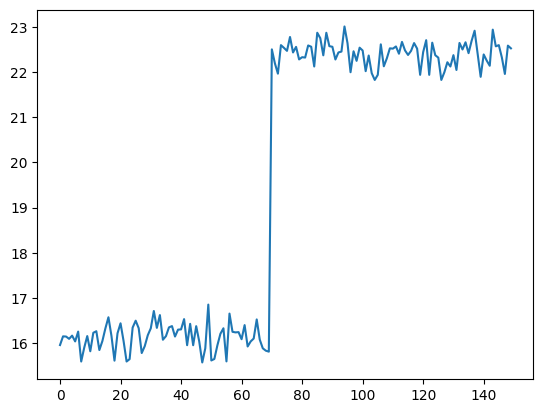

In [130]:
plt.plot(test_scenario_1_drift_y)